# FFT 기반 Adaptive KV Compression

계획서를 그대로 실험으로 옮긴 노트북이다. 흐름은

```
K, V -> rFFT(head_dim) -> frequency selector -> mask -> irFFT -> 기존 attention
```

이고, 기존 모델 weight는 **전부 freeze**, 새로 추가한 selector만 학습한다.

구현은 노트북 옆 모듈 두 개에 있다.

| 파일 | 들어있는 것 |
|---|---|
| `custom_layers.py` | `FreqSelector`, `KVFreqCompressor`, `FFTCompressedCache`, `SparseSpectralCache` |
| `tools.py` | 모델/코퍼스 로딩, 학습 루프, 평가, 메모리 계산, 그림 |

**끼워넣는 지점.** transformers v5의 `Qwen3Attention.forward`는 RoPE를 적용한 뒤 딱 한 줄로
`past_key_values.update(key_states, value_states, layer_idx)`를 부르고 그 반환값으로 attention을
계산한다. 그래서 `DynamicCache.update`만 감싸면 "캐시에 들어가는 KV"와 "attention이 보는 KV"를
한꺼번에 바꿀 수 있다. 모델 코드는 한 줄도 건드리지 않는다.

**커널.** torch가 들어있는 커널이어야 한다 (이 리포의 `.venv`에는 torch가 없다).
`dxo (torch 2.14 cu130)` 커널을 쓴다.

**순서.** 2절에서 가설을 먼저 검증한 다음 학습에 들어간다. "FFT basis에 쓸 만한 sparsity가
있는가"가 거짓이면 selector를 아무리 잘 학습해도 의미가 없으므로, 그 숫자를 먼저 본다.

## 0. 설정

In [1]:
%load_ext autoreload
%autoreload 2

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch

import tools
from custom_layers import FFTCompressedCache, KVFreqCompressor, SparseSpectralCache

# ---------------------------------------------------------------- 실험 설정
MODEL = "Qwen/Qwen3-0.6B"   # bf16. FP8 체크포인트는 selector로 역전파가 안 되므로 쓰지 않는다
CORPUS = "gutenberg"        # "tinystories" 또는 로컬 .txt 경로도 된다
SEQ_LEN = 256
BATCH_SIZE = 2
N_BATCHES = 100             # 학습 90 + 검증 10
EPOCHS = 3
LR = 3e-4

QUICK = False               # True면 아래 값으로 줄여서 돌린다 (구조 확인용)
if QUICK:
    SEQ_LEN, BATCH_SIZE, N_BATCHES, EPOCHS = 128, 1, 20, 1

RESULTS = Path("results")
(RESULTS / "selectors").mkdir(parents=True, exist_ok=True)
summary: dict = {}          # 마지막에 json으로 떨어뜨릴 측정값들

tools.set_seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

2.14.1+cu130 NVIDIA GeForce RTX 5080


## 1. 모델과 데이터

teacher와 student는 **같은 weight**다. 차이는 캐시가 KV를 그대로 흘려보내는지, spectral filter를
통과시키는지 뿐이다. 그래서 측정되는 모든 차이는 압축 탓이라고 말할 수 있다.

In [2]:
model, tok = tools.load_model(MODEL)
info = tools.describe_model(model)
info

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

{'layers': 28,
 'hidden': 1024,
 'q_heads': 16,
 'kv_heads': 8,
 'head_dim': 128,
 'n_freq': 65,
 'vocab': 151936,
 'dtype': 'torch.bfloat16'}

In [3]:
# freeze 확인. 학습 가능한 파라미터가 하나라도 남아 있으면 실험이 성립하지 않는다.
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable in base model: {n_train}  (0이어야 한다)")
print(f"head_dim={info['head_dim']}  ->  rFFT 계수 {info['n_freq']}개 (bin 0 .. {info['head_dim']//2})")

trainable in base model: 0  (0이어야 한다)
head_dim=128  ->  rFFT 계수 65개 (bin 0 .. 64)


In [4]:
text = tools.load_text(CORPUS)
batches = tools.make_batches(tok, text, seq_len=SEQ_LEN, batch_size=BATCH_SIZE,
                             n_batches=N_BATCHES, device=model.device)
n_val = max(2, N_BATCHES // 10)
train_batches, val_batches = batches[:-n_val], batches[-n_val:]
print(f"{len(text):,} chars -> {len(batches)} batches of {tuple(batches[0].shape)}"
      f"  (train {len(train_batches)} / val {len(val_batches)})")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (174851 > 131072). Running this sequence through the model will result in indexing errors


748,167 chars -> 100 batches of (2, 256)  (train 90 / val 10)


## 2. 가설부터 점검한다

핵심 가설은 "K/V latent를 FFT basis로 보면 downstream 예측에 필요한 정보가 **적은 수의 주파수에
모여 있다**"는 것이다. 이건 학습 없이 바로 측정할 수 있다.

1. **에너지 분포** — 크기 순 상위 m개 계수에 전체 에너지의 몇 %가 모이는가. 1에 빨리 붙으면 sparse하다.
2. **truncation 민감도** — 학습 없이 계수를 잘라냈을 때 출력이 얼마나 깨지는가.
3. **레이어별 민감도** — 한 레이어씩만 잘라서, 어디가 약한 고리인지 찾는다.

2번과 3번의 기준선 세 개를 계속 쓴다.

| mode | 뜻 |
|---|---|
| `energy` | 계수 크기 상위 k개. 학습 없는 **적응형** 기준선 (selector가 이겨야 하는 상대) |
| `lowpass` | 낮은 주파수 k개. 학습 없는 **정적** 기준선 |
| `random` | 무작위 k개. 대조군 |

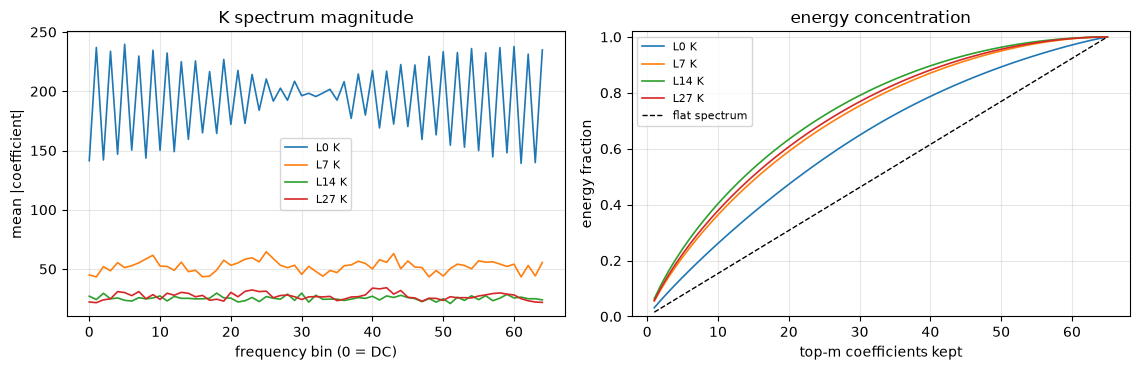

K: top-32/65 계수가 담는 에너지 평균 0.790 (최소 0.638, 최대 0.841)
V: top-32/65 계수가 담는 에너지 평균 0.839 (최소 0.832, 최대 0.841)

완전히 평탄한 스펙트럼이면 이 값이 0.5다. 1에 가까울수록 sparse하다.


In [5]:
# 레이어별 K/V 스펙트럼 통계
stats = tools.spectrum_stats(model, val_batches[0])

probe_layers = [0, info["layers"] // 4, info["layers"] // 2, info["layers"] - 1]
fig, (ax_mag, ax_cum) = plt.subplots(1, 2, figsize=(11.5, 3.8))
for layer in probe_layers:
    ax_mag.plot(stats["mean_mag"][(layer, "k")], label=f"L{layer} K", lw=1.2)
    ax_cum.plot(range(1, info["n_freq"] + 1), stats["energy_curve"][(layer, "k")],
                label=f"L{layer} K", lw=1.2)
ax_cum.plot([1, info["n_freq"]], [1 / info["n_freq"], 1.0], "k--", lw=1,
            label="flat spectrum")
ax_mag.set(xlabel="frequency bin (0 = DC)", ylabel="mean |coefficient|",
           title="K spectrum magnitude")
ax_cum.set(xlabel="top-m coefficients kept", ylabel="energy fraction",
           title="energy concentration", ylim=(0, 1.02))
for a in (ax_mag, ax_cum):
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 숫자로도: 계수 절반만 남겼을 때 남는 에너지
half = info["n_freq"] // 2
for which in ("k", "v"):
    kept = [float(stats["energy_curve"][(l, which)][half - 1]) for l in range(info["layers"])]
    print(f"{which.upper()}: top-{half}/{info['n_freq']} 계수가 담는 에너지 "
          f"평균 {sum(kept)/len(kept):.3f} (최소 {min(kept):.3f}, 최대 {max(kept):.3f})")
print("\n완전히 평탄한 스펙트럼이면 이 값이 0.5다. 1에 가까울수록 sparse하다.")

에너지만으로는 "잘라도 되는가"를 알 수 없다. 작은 계수가 downstream에 결정적일 수도 있으니까.
그래서 실제로 잘라보고 KL을 잰다. 아래는 **학습 전** 숫자다 — selector가 넘어야 할 바닥선.

In [6]:
compressor = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
print("selector 파라미터:", sum(p.numel() for p in compressor.parameters()),
      f"(base model의 {sum(p.numel() for p in compressor.parameters())/sum(p.numel() for p in model.parameters()):.2%})")

baseline_rows = tools.sweep_ratios(
    model, compressor, val_batches,
    ratios=(1.0, 0.9375, 0.875, 0.75, 0.5, 0.25),
    modes=("energy", "lowpass", "random"),
)
summary["untrained_truncation"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
    for r in baseline_rows
]

selector 파라미터: 2784824 (base model의 0.47%)
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.9375  kl=   2.8235 agree=0.227 ppl=      504.00
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.9375  kl=   1.8198 agree=0.347 ppl=      198.80
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59
  random keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  random keep=0.9375  kl=   5.9304 agree=0.073 ppl=    10266.47
  random keep=0.875   kl=   7.0395 agree=0.054 ppl=    29874.

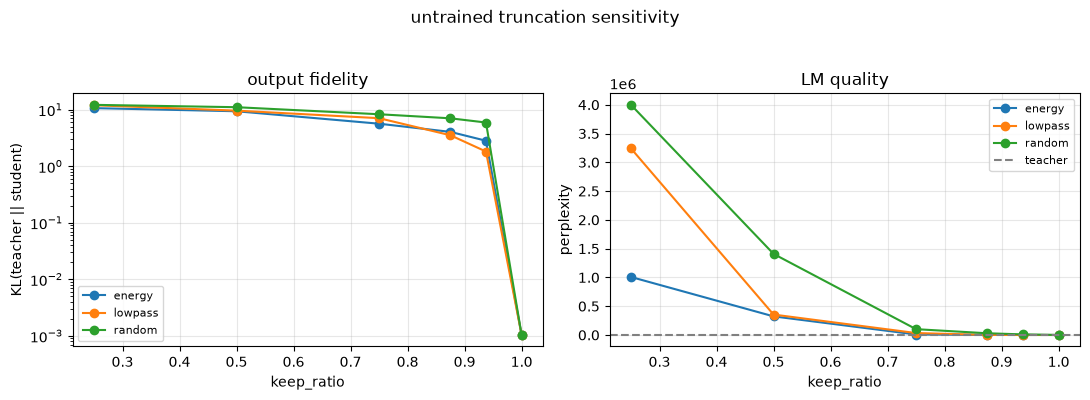

In [7]:
tools.plot_tradeoff(baseline_rows)
plt.suptitle("untrained truncation sensitivity", y=1.04)
plt.tight_layout()
plt.show()

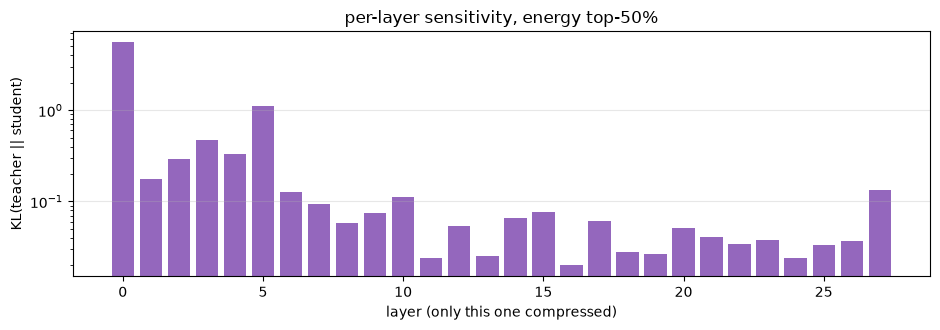

가장 민감한 5개 레이어: [(0, 5.5229), (5, 1.1232), (3, 0.4671), (4, 0.3291), (2, 0.291)]
가장 둔감한 5개 레이어: [(19, 0.0268), (13, 0.0252), (11, 0.0243), (24, 0.0238), (16, 0.02)]


In [8]:
# 한 번에 한 레이어씩만 압축해, 어디가 약한 고리인지 본다.
sens = tools.layer_sensitivity(model, compressor, val_batches[:2], keep_ratio=0.5, mode="energy")
summary["layer_sensitivity"] = sens

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.bar([r["layer"] for r in sens], [r["kl"] for r in sens], color="tab:purple")
ax.set(xlabel="layer (only this one compressed)", ylabel="KL(teacher || student)",
       title="per-layer sensitivity, energy top-50%", yscale="log")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

ranked = sorted(sens, key=lambda r: -r["kl"])
print("가장 민감한 5개 레이어:", [(r["layer"], round(r["kl"], 4)) for r in ranked[:5]])
print("가장 둔감한 5개 레이어:", [(r["layer"], round(r["kl"], 4)) for r in ranked[-5:]])

## 3. Selector와 캐시 sanity check

학습을 시작하기 전에 세 가지를 확인한다.

1. `mode="off"`면 압축 캐시가 원본과 **비트 단위로 같은** 출력을 내는가 (= 배선이 맞는가).
2. 초기화 상태의 mask가 1에 가까운가 (= student가 teacher에서 출발하는가).
3. mask를 전부 1로 둔 rFFT→irFFT 왕복이 얼마나 오차를 내는가 (= 측정의 바닥 노이즈).

In [9]:
# 1) off 모드는 완전 통과여야 한다
off = tools.evaluate(model, compressor, val_batches[:2], mode="off")
print(f"off      : KL={off['kl']:.3e}  agree={off['agree']:.4f}   <- 0 / 1.0 이어야 한다")

# 3) keep=100% 왕복 오차 = 측정 바닥선
full = tools.evaluate(model, compressor, val_batches[:2], mode="topk", keep_ratio=1.0)
print(f"keep 100%: KL={full['kl']:.3e}  agree={full['agree']:.4f}   <- fft 왕복 + bf16 반올림")

# 2) 초기 mask. FreqSelector는 마지막 Linear의 weight=0, bias=init_logit으로 시작한다.
init = tools.evaluate(model, compressor, val_batches[:2], mode="soft")
print(f"soft@init: KL={init['kl']:.3e}  agree={init['agree']:.4f}  usage={init['usage']:.4f}")
summary["sanity"] = {"off_kl": off["kl"], "roundtrip_kl": full["kl"],
                     "soft_init_kl": init["kl"], "soft_init_usage": init["usage"]}

off      : KL=0.000e+00  agree=1.0000   <- 0 / 1.0 이어야 한다
keep 100%: KL=1.032e-03  agree=0.9824   <- fft 왕복 + bf16 반올림
soft@init: KL=2.536e-03  agree=0.9648  usage=0.9820


## 4. Stage 1 — soft mask 학습

loss는 계획서 그대로다.

$$L = L_{KD} + \lambda_{sparse}\,\overline{mask} + \lambda_{budget}\,\mathrm{relu}(\overline{mask} - r_{target})^2$$

`train_selectors`는 처음 `warmup` 스텝 동안 sparsity/budget 계수를 0에서 선형으로 올린다.
초기 mask가 1에 가까워 budget 항의 기울기가 크고, 램프 없이 때리면 첫 스텝에서 selector가
통째로 망가진다 (KL이 0.003에서 1.2로 튄다).

In [ ]:
TARGET_RATIO = 0.5

tools.set_seed(0)
compressor_soft = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
history = tools.train_selectors(
    model, compressor_soft, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="soft",
    lambda_sparse=0.01,
    target_ratio=TARGET_RATIO,
    lambda_budget=5.0,
    warmup=20,
    log_every=max(1, len(train_batches) // 4),
)
torch.save(compressor_soft.state_dict(), RESULTS / "selectors" / "stage1_soft.pt")
print("peak GPU MiB:", torch.cuda.max_memory_allocated() / 2**20)

step    0  loss 0.13781  KL 0.00336  usage 0.982
step   22  loss 2.43821  KL 0.03568  usage 0.942
step   44  loss 1.89272  KL 0.29449  usage 0.814
step   66  loss 1.57227  KL 0.61416  usage 0.686
step   88  loss 1.01474  KL 0.37721  usage 0.605
step  110  loss 0.98045  KL 0.45337  usage 0.573
step  132  loss 0.81982  KL 0.37205  usage 0.547
step  154  loss 0.79068  KL 0.39706  usage 0.529
step  176  loss 0.75591  KL 0.37930  usage 0.523
step  198  loss 0.73864  KL 0.40575  usage 0.506
step  220  loss 0.68900  KL 0.37909  usage 0.497
step  242  loss 0.64317  KL 0.36816  usage 0.482
step  264  loss 0.67848  KL 0.40998  usage 0.480
peak GPU MiB: 4860.10205078125


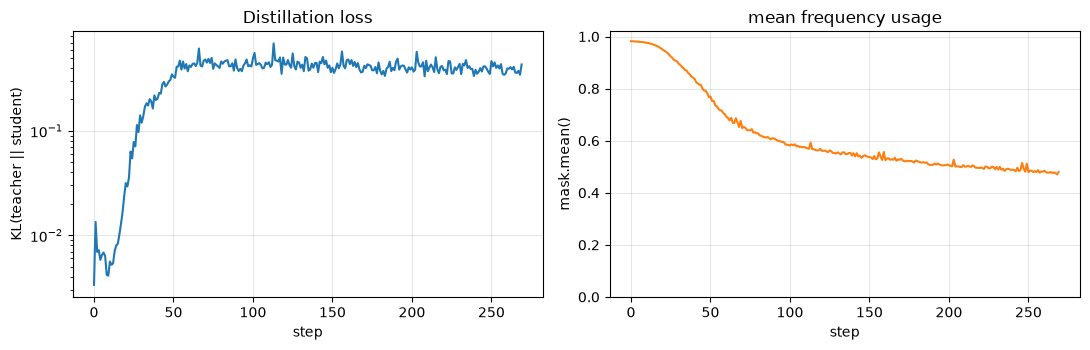

In [11]:
tools.plot_training(history)
plt.tight_layout()
plt.show()

soft mask: usage=0.475  KL=0.4160  agree=0.639  ppl=46.58 (teacher 36.46)


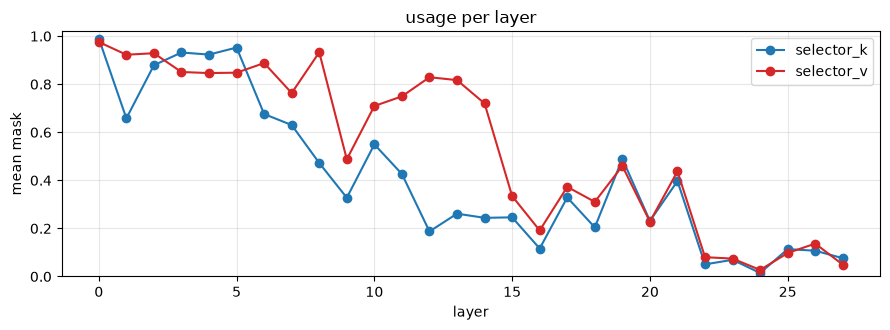

In [12]:
soft = tools.evaluate(model, compressor_soft, val_batches, mode="soft")
print(f"soft mask: usage={soft['usage']:.3f}  KL={soft['kl']:.4f}  "
      f"agree={soft['agree']:.3f}  ppl={soft['ppl']:.2f} (teacher {soft['ppl_teacher']:.2f})")
summary["stage1_soft"] = {k: soft[k] for k in ("kl", "agree", "ppl", "ppl_teacher", "usage")}

tools.plot_layer_usage(soft["usage_by_layer"])
plt.tight_layout()
plt.show()

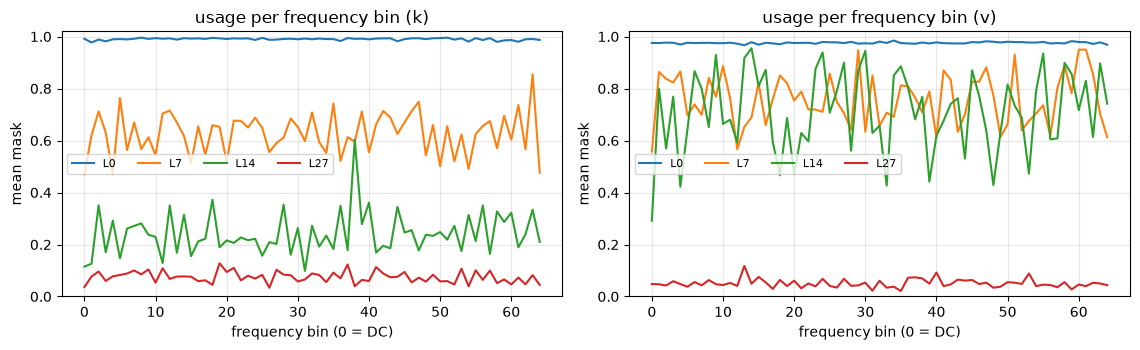

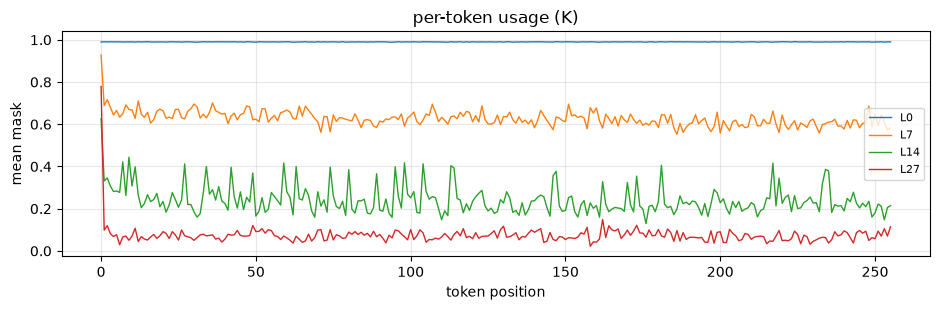

In [13]:
# selector가 어떤 주파수를 중요하게 보는가. 레이어마다 다른 패턴이 나오는지 본다.
compressor_soft.reset_log()
compressor_soft.mode, compressor_soft.collect = "soft", True
with torch.no_grad():
    cache = FFTCompressedCache(compressor_soft, config=model.config)
    tools.forward_logits(model, val_batches[0], cache)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
tools.plot_freq_profile(compressor_soft, probe_layers, "k", ax=axes[0])
tools.plot_freq_profile(compressor_soft, probe_layers, "v", ax=axes[1])
plt.tight_layout()
plt.show()

# 토큰 위치에 따라 사용률이 달라지는가 (= 진짜 "adaptive"인가)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for layer in probe_layers:
    ax.plot(compressor_soft.per_token_usage(layer, "k"), lw=1, label=f"L{layer}")
ax.set(xlabel="token position", ylabel="mean mask", title="per-token usage (K)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
del cache

### soft -> hard 간극

soft mask는 계수를 "약하게" 만들지 실제로 **버리지** 않는다. 캐시 바이트를 줄이려면 0/1 선택이
필요하다. 학습된 soft selector의 점수를 그대로 top-k로 잘라보면 그 간극이 보인다.

    topk keep=1.0     kl=   0.0010 agree=0.977 ppl=       36.41
    topk keep=0.875   kl=   4.2475 agree=0.139 ppl=     1970.07
    topk keep=0.75    kl=   6.7659 agree=0.063 ppl=    22568.07
    topk keep=0.5     kl=   8.4251 agree=0.018 ppl=   101716.61
    topk keep=0.25    kl=   8.7785 agree=0.015 ppl=   135270.12
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59


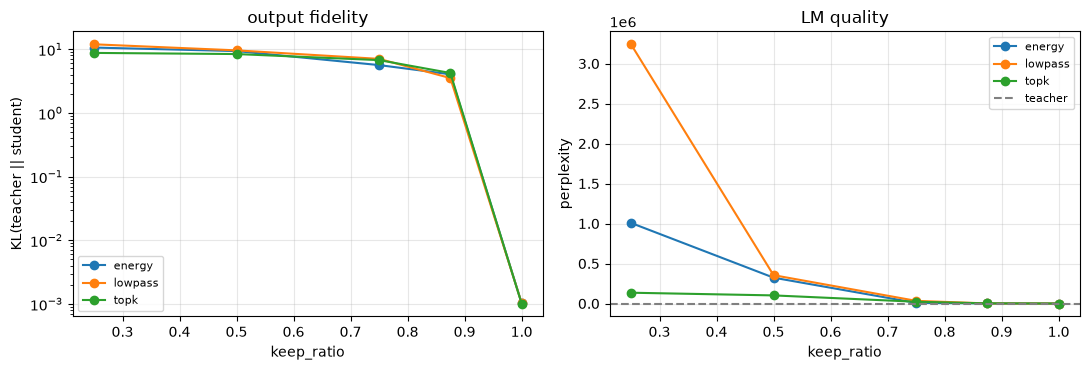

In [14]:
gap_rows = tools.sweep_ratios(
    model, compressor_soft, val_batches,
    ratios=(1.0, 0.875, 0.75, 0.5, 0.25),
    modes=("topk", "energy", "lowpass"),
)
summary["stage1_to_hard"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl")} for r in gap_rows
]
tools.plot_tradeoff(gap_rows)
plt.tight_layout()
plt.show()

## 5. Stage 2 — hard selection 자체를 학습

soft로 학습한 selector를 사후에 잘라내는 대신, **처음부터 0/1 mask로 학습**한다.
`straight_through=True`가 forward에서는 hard mask를, backward에서는 sigmoid의 기울기를 쓰게 해
top-k 선택을 통과하는 gradient를 만들어 준다.

비율이 top-k로 고정되므로 sparsity/budget 항은 끈다 (`lambda_sparse=0, target_ratio=None`).
남는 것은 순수 distillation loss 하나다: *이 예산 안에서 무엇을 고를 것인가*.

In [15]:
RATIOS = (0.9375, 0.875, 0.75, 0.5) if not QUICK else (0.875, 0.5)

stage2 = {}
rows_learned = []
for ratio in RATIOS:
    tools.set_seed(0)
    comp = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
    print(f"\n=== keep_ratio {ratio} ===")
    tools.train_selectors(
        model, comp, train_batches,
        epochs=EPOCHS, lr=LR,
        mode="topk", keep_ratio=ratio, straight_through=True,
        lambda_sparse=0.0, target_ratio=None,
        log_every=max(1, len(train_batches) // 2),
    )
    row = tools.evaluate(model, comp, val_batches, mode="topk", keep_ratio=ratio,
                         collect_usage=False)
    row.pop("usage_by_layer", None)
    row["mode"] = "topk (learned, STE)"
    rows_learned.append(row)
    stage2[ratio] = comp
    torch.save(comp.state_dict(), RESULTS / "selectors" / f"stage2_topk_{ratio}.pt")
    print(f"-> KL={row['kl']:.4f} agree={row['agree']:.3f} ppl={row['ppl']:.2f}")


=== keep_ratio 0.9375 ===
step    0  loss 1.73666  KL 1.73666  usage 0.938
step   45  loss 1.53713  KL 1.53713  usage 0.938
step   90  loss 1.55255  KL 1.55255  usage 0.938
step  135  loss 1.59117  KL 1.59117  usage 0.938
step  180  loss 2.09933  KL 2.09933  usage 0.938
step  225  loss 1.67548  KL 1.67548  usage 0.938
-> KL=1.6943 agree=0.368 ppl=143.88

=== keep_ratio 0.875 ===
step    0  loss 3.54492  KL 3.54492  usage 0.877
step   45  loss 2.64537  KL 2.64537  usage 0.877
step   90  loss 2.17606  KL 2.17606  usage 0.877
step  135  loss 2.51786  KL 2.51786  usage 0.877
step  180  loss 2.71501  KL 2.71501  usage 0.877
step  225  loss 2.52067  KL 2.52067  usage 0.877
-> KL=2.5639 agree=0.241 ppl=329.30

=== keep_ratio 0.75 ===
step    0  loss 6.58765  KL 6.58765  usage 0.754
step   45  loss 3.65003  KL 3.65003  usage 0.754
step   90  loss 3.44972  KL 3.44972  usage 0.754
step  135  loss 2.96312  KL 2.96312  usage 0.754
step  180  loss 3.00125  KL 3.00125  usage 0.754
step  225  loss 2

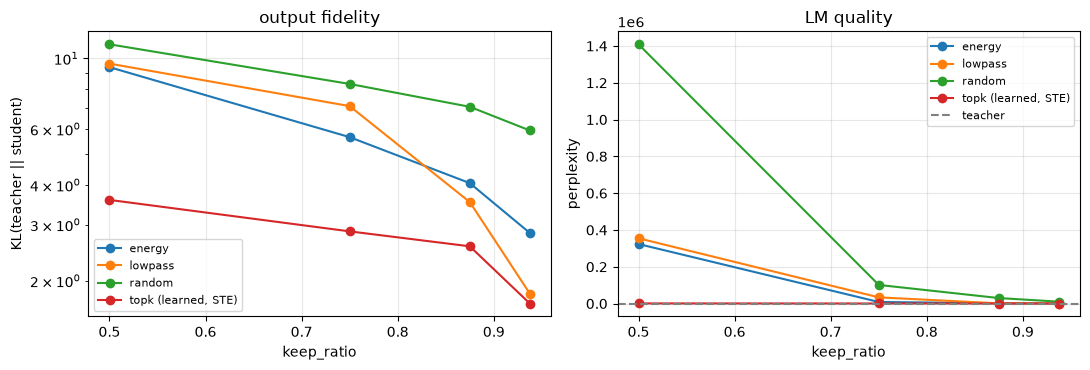

   keep  learned KL   energy KL  lowpass KL   random KL
 0.9375      1.6943      2.8235      1.8198      5.9304
  0.875      2.5639      4.0510      3.5322      7.0395
   0.75      2.8568      5.6512      7.0741      8.3057
    0.5      3.5876      9.3800      9.6242     11.0672


In [16]:
# 학습된 선택 vs 학습 없는 기준선들을 같은 축에 올린다.
rows_ref = [r for r in baseline_rows if r["keep_ratio"] in RATIOS]
trade_rows = rows_learned + rows_ref
summary["stage2"] = [{k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
                     for r in trade_rows]

tools.plot_tradeoff(trade_rows)
plt.tight_layout()
plt.show()

print(f"{'keep':>7} {'learned KL':>11} {'energy KL':>11} {'lowpass KL':>11} {'random KL':>11}")
for ratio in RATIOS:
    def pick(mode):
        hit = [r for r in trade_rows if r["mode"] == mode and r["keep_ratio"] == ratio]
        return f"{hit[0]['kl']:.4f}" if hit else "-"
    print(f"{ratio:>7} {pick('topk (learned, STE)'):>11} {pick('energy'):>11} "
          f"{pick('lowpass'):>11} {pick('random'):>11}")

## 6. 어느 레이어에 예산을 쓸 것인가

2절의 레이어별 민감도를 실제 설정으로 옮긴다. 앞쪽 레이어 N개를 압축에서 제외하면 — 즉 예산을
둔감한 레이어에만 쓰면 — 같은 평균 압축률에서 품질이 어떻게 달라지는가.

In [17]:
SKIPS = (0, 2, 4, 8, 12) if not QUICK else (0, 4)
KEEP = 0.5

skip_rows = []
for skip in SKIPS:
    compressor.active_layers = set(range(skip, info["layers"]))
    r = tools.evaluate(model, compressor, val_batches, mode="energy", keep_ratio=KEEP,
                       collect_usage=False)
    # 압축한 레이어만 세어 실효 평균 사용률을 다시 계산한다
    compressed = info["layers"] - skip
    r["effective_keep"] = (compressed * KEEP + skip * 1.0) / info["layers"]
    r["skip"] = skip
    skip_rows.append(r)
    print(f"skip={skip:>2} ({compressed} layers @ keep {KEEP}) "
          f"-> 실효 사용률 {r['effective_keep']:.3f}  KL={r['kl']:.4f}  ppl={r['ppl']:.2f}")
compressor.active_layers = set(range(info["layers"]))
summary["layer_budget"] = [{k: r[k] for k in ("skip", "effective_keep", "kl", "agree", "ppl")}
                           for r in skip_rows]

skip= 0 (28 layers @ keep 0.5) -> 실효 사용률 0.500  KL=9.3800  ppl=323562.17
skip= 2 (26 layers @ keep 0.5) -> 실효 사용률 0.536  KL=5.6522  ppl=9368.67
skip= 4 (24 layers @ keep 0.5) -> 실효 사용률 0.571  KL=4.7382  ppl=3900.34
skip= 8 (20 layers @ keep 0.5) -> 실효 사용률 0.643  KL=1.8579  ppl=228.22
skip=12 (16 layers @ keep 0.5) -> 실효 사용률 0.714  KL=1.0848  ppl=107.55


In [18]:
# 가장 좋았던 skip 값으로 다시 학습해, 레이어 선택과 학습을 합친 효과를 본다.
best_skip = min(skip_rows, key=lambda r: r["kl"])["skip"]
print("best skip:", best_skip)

tools.set_seed(0)
comp_skip = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
comp_skip.active_layers = set(range(best_skip, info["layers"]))
tools.train_selectors(
    model, comp_skip, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="topk", keep_ratio=KEEP, straight_through=True,
    lambda_sparse=0.0, target_ratio=None,
    log_every=max(1, len(train_batches) // 2),
)
best = tools.evaluate(model, comp_skip, val_batches, mode="topk", keep_ratio=KEEP,
                      collect_usage=False)
print(f"skip={best_skip} + 학습: KL={best['kl']:.4f} agree={best['agree']:.3f} "
      f"ppl={best['ppl']:.2f} (teacher {best['ppl_teacher']:.2f})")
torch.save(comp_skip.state_dict(), RESULTS / "selectors" / f"stage3_skip{best_skip}_keep{KEEP}.pt")
summary["layer_budget_trained"] = {"skip": best_skip, "keep": KEEP,
                                   **{k: best[k] for k in ("kl", "agree", "ppl", "ppl_teacher")}}

best skip: 12
step    0  loss 1.53063  KL 1.53063  usage 0.492
step   45  loss 0.51318  KL 0.51318  usage 0.492
step   90  loss 0.44518  KL 0.44518  usage 0.492
step  135  loss 0.41150  KL 0.41150  usage 0.492
step  180  loss 0.36777  KL 0.36777  usage 0.492
step  225  loss 0.36134  KL 0.36134  usage 0.492
skip=12 + 학습: KL=0.4321 agree=0.635 ppl=48.19 (teacher 36.46)


## 7. Stage 3 — 실제 KV cache 압축

여기까지의 `FFTCompressedCache`는 **재구성된 D차원 실수 벡터**를 저장한다. 즉 정보량은 줄었지만
바이트는 그대로다. 실제로 줄이려면 주파수 index와 complex 계수만 들고 있어야 한다.

`SparseSpectralCache`가 그걸 한다. 토큰·head마다 상위 `keep`개를 골라

```
idx  : int16        (B, H, S, keep)
re   : bfloat16     (B, H, S, keep)
im   : bfloat16     (B, H, S, keep)
```

로 저장하고, attention에 줄 때만 0으로 채운 spectrum에 scatter해 irFFT한다.

**오버헤드를 정직하게 세야 한다.** 계수 하나는 실수부+허수부로 4바이트인데, 원본은 bf16 2바이트
한 칸이다. 즉 계수 **하나를 남기면 원본 두 칸 값을 쓴다**. rFFT 계수가 `D/2+1`개이므로
"계수 절반"은 바이트로 "원본 전체와 거의 같다". 거기에 어느 주파수를 골랐는지도 저장해야 한다.

In [19]:
seq = SEQ_LEN
print(f"seq_len={seq}, {info['layers']} layers, {info['kv_heads']} kv heads, head_dim={info['head_dim']}\n")
dense = tools.dense_kv_bytes(info, seq)
print(f"{'keep':>5} {'ratio':>7} {'bitmask':>12} {'vs dense':>9} {'index':>12} {'vs dense':>9}")
mem_rows = []
for keep in (65, 48, 32, 24, 16, 8, 4):
    keep = min(keep, info["n_freq"])
    bm = tools.spectral_kv_bytes(info, seq, keep, index_scheme="bitmask")
    ix = tools.spectral_kv_bytes(info, seq, keep, index_scheme="index")
    mem_rows.append({"keep": keep, "ratio": keep / info["n_freq"],
                     "bitmask": bm, "index": ix, "dense": dense})
    print(f"{keep:>5} {keep/info['n_freq']:>7.3f} {bm/2**20:>10.2f}MB {bm/dense:>8.2f}x "
          f"{ix/2**20:>10.2f}MB {ix/dense:>8.2f}x")
print(f"\ndense: {dense/2**20:.2f}MB")
summary["memory_table"] = mem_rows

seq_len=256, 28 layers, 8 kv heads, head_dim=128

 keep   ratio      bitmask  vs dense        index  vs dense
   65   1.000      29.42MB     1.05x      42.66MB     1.52x
   48   0.738      21.98MB     0.79x      31.50MB     1.12x
   32   0.492      14.98MB     0.54x      21.00MB     0.75x
   24   0.369      11.48MB     0.41x      15.75MB     0.56x
   16   0.246       7.98MB     0.29x      10.50MB     0.38x
    8   0.123       4.48MB     0.16x       5.25MB     0.19x
    4   0.062       2.73MB     0.10x       2.62MB     0.09x

dense: 28.00MB


In [20]:
# 실제 캐시로 디코딩해 본다. 바이트는 캐시가 들고 있는 텐서에서 직접 센다.
PROMPT = "Explain in two sentences why the sky is blue."
KEEP_N = 32

ref = tools.greedy_generate(model, tok, PROMPT, max_new_tokens=48)
print(f"[원본]  {ref['tok_per_s']:.1f} tok/s\n{ref['text']!r}\n")

for comp_name, comp_obj in (("untrained", compressor), (f"trained skip{best_skip}", comp_skip)):
    out = tools.greedy_generate(
        model, tok, PROMPT, max_new_tokens=48,
        make_cache=lambda c=comp_obj: SparseSpectralCache(c, keep=KEEP_N, config=model.config),
    )
    print(f"[sparse {KEEP_N}/{info['n_freq']}, {comp_name}]  {out['tok_per_s']:.1f} tok/s  "
          f"cache {out['footprint_bytes']/2**20:.2f}MB\n{out['text']!r}\n")
    summary[f"stage3_gen_{comp_name}"] = {k: out[k] for k in
                                          ("text", "tok_per_s", "footprint_bytes")}
summary["stage3_gen_ref"] = {k: ref[k] for k in ("text", "tok_per_s")}

[원본]  118.5 tok/s
"The sky appears blue because of the way light interacts with the Earth's atmosphere, where shorter wavelengths of light (blue) are scattered more efficiently than longer wavelengths (red and orange). This scattering causes the blue light to be scattered in all directions"

[sparse 32/65, untrained]  64.1 tok/s  cache 5.74MB
'лотymrythofzeotom.typstitute-tableathingatory่ายotenof-#elif-extr.-mapb-- f. odinousetically openL,abcdefghijklmnopumer-wheel seneut- Hartfordace board mutual痿Taylor tym-ай'

[sparse 32/65, trained skip12]  65.7 tok/s  cache 5.74MB
' in the.. \n\n. \n\n. \n\n...,.... \n\n......,. in. ...... in and-witherens a.... the.....'



`tok/s`가 원본보다 느린 것은 예상된 결과다. 매 스텝 rFFT/irFFT와 scatter를 추가로 돌리고,
게다가 `SparseSpectralCache`는 과거 전체를 매번 복원한다 (즉 O(S) 작업을 O(S^2)로 만든다).
이 절의 목적은 속도가 아니라 **압축된 표현만 들고도 디코딩이 돌아가는지**와 **실제 바이트**다.
속도를 재려면 복원을 증분으로 바꾸거나 spectral domain에서 직접 attention을 계산해야 한다.

## 8. 종합

성능 저하 대비 KV cache 감소량이 최종 지표다. `keep` 하나를 고르면 바이트는 계산으로 나오고,
품질은 위에서 측정한 값을 그대로 쓴다.

In [21]:
print(f"teacher perplexity: {soft['ppl_teacher']:.2f}\n")
header = f"{'setting':>34} {'keep':>7} {'KL':>9} {'agree':>7} {'ppl':>12} {'KV bytes':>10}"
print(header)
print("-" * len(header))

def line(name, keep_ratio, row, bytes_ratio=None):
    keep_n = max(1, round(keep_ratio * info["n_freq"]))
    nbytes = tools.spectral_kv_bytes(info, SEQ_LEN, keep_n, index_scheme="bitmask")
    ratio = bytes_ratio if bytes_ratio is not None else nbytes / dense
    print(f"{name:>34} {keep_ratio:>7.3f} {row['kl']:>9.4f} {row['agree']:>7.3f} "
          f"{row['ppl']:>12.2f} {ratio:>9.2f}x")

line("teacher (no compression)", 1.0, {"kl": 0.0, "agree": 1.0, "ppl": soft["ppl_teacher"]}, 1.0)
line("stage1 soft (no byte saving)", 1.0, soft, 1.0)
for row in rows_learned:
    line("stage2 learned top-k", row["keep_ratio"], row)
for row in rows_ref:
    line(f"  baseline {row['mode']}", row["keep_ratio"], row)
line(f"stage2 + skip first {best_skip}", KEEP, best)

(RESULTS / "fft_kv_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(f"\n-> {RESULTS/'fft_kv_summary.json'} 저장")

teacher perplexity: 36.46

                           setting    keep        KL   agree          ppl   KV bytes
------------------------------------------------------------------------------------
          teacher (no compression)   1.000    0.0000   1.000        36.46      1.00x
      stage1 soft (no byte saving)   1.000    0.4160   0.639        46.58      1.00x
              stage2 learned top-k   0.938    1.6943   0.368       143.88      0.99x
              stage2 learned top-k   0.875    2.5639   0.241       329.30      0.93x
              stage2 learned top-k   0.750    2.8568   0.214       426.34      0.80x
              stage2 learned top-k   0.500    3.5876   0.134       834.75      0.54x
                   baseline energy   0.938    2.8235   0.227       504.00      0.99x
                   baseline energy   0.875    4.0510   0.135      1728.34      0.93x
                   baseline energy   0.750    5.6512   0.070      8511.84      0.80x
                   baseline energy   0

### 읽는 법과 다음 수

표의 `KV bytes` 열이 이 실험의 손익계산서다. 계수 하나당 실수부+허수부 4바이트를 쓰므로,
**계수를 절반으로 줄여도 바이트는 거의 그대로**다. 실질적 이득은 `keep`이 `n_freq/2`보다 한참
아래로 내려가야 나오고, 품질은 그 전에 먼저 무너진다. 그래서 이 축으로 이득을 보려면

- **계수를 더 작은 dtype으로** — fp8이나 int8 양자화. 2바이트 대신 1바이트면 손익분기점이 두 배로 밀린다.
- **head_dim이 아니라 sequence 축으로 FFT** — 인접 토큰의 K/V는 상관이 높다. 계획서는 head_dim 축을
  명시했지만, KV cache의 실제 중복은 시간 축에 있다. `spectral_filter`를 `transpose` 한 번으로 돌려쓸 수 있다.
- **RoPE 적용 전 K** — RoPE는 차원 i와 i+D/2를 섞어 스펙트럼에 주기 2의 톱니를 만든다 (2절 왼쪽 그림).
  pre-RoPE K를 저장하고 읽을 때 회전시키면 더 매끄러운 스펙트럼을 다룰 수 있다.
- **레이어별 예산 배분** — 6절이 보여주듯 레이어 민감도 차이가 수백 배다. 균일 예산은 낭비다.
- **큰 모델** — head_dim이 같아도 레이어 수와 head 수가 많아지면 중복이 늘어날 수 있다.

가설 자체에 대한 판정은 위 숫자로 한다. `energy`/`lowpass`/`random` 대비 학습된 selector가
얼마나 앞서는지가 "**적응형 선택이 학습 가능한가**"에 대한 답이고, teacher 대비 절대 품질이
"**FFT basis에 쓸 만한 sparsity가 있는가**"에 대한 답이다. 두 질문은 따로 답이 나올 수 있다.